In [177]:
import pandas as pd
import numpy as np
import re
import requests
from bs4 import BeautifulSoup
import pathlib as path
import matplotlib.pyplot as plt
import seaborn as sns


In [178]:
url_train = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
url_test = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.test"

df_train = pd.read_csv(url_train, header=None)

df_test = pd.read_csv(url_test, header=None, skiprows=1)

print(df_train.shape)
print(df_test.shape)

(32561, 15)
(16281, 15)


In [179]:
df_train.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [180]:
df_test.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K.
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K.
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K.
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K.
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K.


In [181]:
# add 15 columns names 
columns = [
    "age",
    "workclass",
    "fnlwgt",
    "education",
    "education_num",
    "marital_status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "capital_gain",
    "capital_loss",
    "hours_per_week",
    "native_country",
    "income"
]
df_train.columns = columns
df_test.columns = columns


In [182]:
 # add source split 
df_train["source_split"]="train"
df_test["source_split"]="test"

In [183]:
 #combine both
df = pd.concat(
    [df_train,df_test],
    ignore_index=True
)
# check 
print("combined data shape:",df.shape)

combined data shape: (48842, 16)


In [184]:
# save the raw combined dataset 
df.to_csv("../data/adult_income_raw.csv",
          index = False)

#  Raw inspection

In [185]:
# raw data inspection 

df.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,source_split
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K,train
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K,train
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K,train
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K,train
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K,train


In [186]:
# find shape 
df.shape

(48842, 16)

In [187]:
# define columns
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education_num',
       'marital_status', 'occupation', 'relationship', 'race', 'sex',
       'capital_gain', 'capital_loss', 'hours_per_week', 'native_country',
       'income', 'source_split'],
      dtype='str')

In [188]:
# define information
df.info

<bound method DataFrame.info of        age          workclass  fnlwgt   education  education_num  \
0       39          State-gov   77516   Bachelors             13   
1       50   Self-emp-not-inc   83311   Bachelors             13   
2       38            Private  215646     HS-grad              9   
3       53            Private  234721        11th              7   
4       28            Private  338409   Bachelors             13   
...    ...                ...     ...         ...            ...   
48837   39            Private  215419   Bachelors             13   
48838   64                  ?  321403     HS-grad              9   
48839   38            Private  374983   Bachelors             13   
48840   44            Private   83891   Bachelors             13   
48841   35       Self-emp-inc  182148   Bachelors             13   

            marital_status          occupation     relationship  \
0            Never-married        Adm-clerical    Not-in-family   
1       Married-c

In [189]:
# find missing values
(df == "?").sum()

age               0
workclass         0
fnlwgt            0
education         0
education_num     0
marital_status    0
occupation        0
relationship      0
race              0
sex               0
capital_gain      0
capital_loss      0
hours_per_week    0
native_country    0
income            0
source_split      0
dtype: int64

In [190]:
# find duplicates
df.duplicated().sum()

np.int64(29)

In [191]:
# missing value conert

df = df.replace("?",np.nan) 

In [192]:
# define isnull value

df.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education_num     0
marital_status    0
occupation        0
relationship      0
race              0
sex               0
capital_gain      0
capital_loss      0
hours_per_week    0
native_country    0
income            0
source_split      0
dtype: int64

# standardize whiteshapce

In [193]:
# identify categorical columns
categorical_columns = df.select_dtypes(include="object").columns

# remove leading and trailing whitespace
for col in categorical_columns:
    df[col] = df[col].str.strip()

print("whitespace cleaning completed")    

C:\Users\disha\AppData\Local\Temp\ipykernel_40272\3331764390.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns


whitespace cleaning completed


In [194]:
df.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,source_split
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K,train
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K,train
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K,train
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K,train
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K,train


In [195]:
# Handle missing categorical values

missing_columns = [
    "workclass",
    "occupation",
    "native_country"
]

for col in missing_columns:
    df[col] = df[col].fillna("Unknown")

print("categorical missing values handle")    

categorical missing values handle


In [196]:
df[missing_columns].isnull().sum()

workclass         0
occupation        0
native_country    0
dtype: int64

In [197]:
# convert numeric values

numeric_columns = [
    "age",
    "fnlwgt",
    "education_num",
    "capital_loss",
    "hours_per_week"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col],errors="coerce")

# check
df[numeric_columns].dtypes    

age               int64
fnlwgt            int64
education_num     int64
capital_loss      int64
hours_per_week    int64
dtype: object

In [198]:
# validate numeric data

df[numeric_columns].describe()

# for negative values

for col in numeric_columns:
    print(f"\n{col}")
    print("Minimum:",df[col].min())


age
Minimum: 17

fnlwgt
Minimum: 12285

education_num
Minimum: 1

capital_loss
Minimum: 0

hours_per_week
Minimum: 1


In [199]:
# imposssible core values

print("Age <=0:",(df["age"]<= 0).sum())
print("Hours < 0:",(df["hours_per_week"]< 0).sum())
print("Capital gain < 0:",(df["capital_gain"]< 0).sum())
print("Capital loss < 0:",(df["capital_loss"]< 0).sum())

Age <=0: 0
Hours < 0: 0
Capital gain < 0: 0
Capital loss < 0: 0


In [200]:
# normalize the income columns

df ["income"]= df["income"].str.replace(".","",regex=False)

# check the unique values
df["income"].unique()

<StringArray>
['<=50K', '>50K']
Length: 2, dtype: str

In [201]:
# create high income

df["high_income"]=(df["income"]== ">50k").astype(int)

# check the result
df[["income","high_income"]].head(10)

,income,high_income
0,<=50K,0
1,<=50K,0
2,<=50K,0
3,<=50K,0
4,<=50K,0
5,<=50K,0
6,<=50K,0
7,>50K,0
8,>50K,0
9,>50K,0


In [202]:
high_income_rate = df["high_income"].mean() * 100

print(f"Records with income above $50K: {high_income_rate:.2f}%")

Records with income above $50K: 0.00%


In [203]:
# Create weekly working-hour groups

hour_bins = [0, 19, 34, 39, 40, 49, np.inf]

hour_labels = [
    "<20",
    "20-34",
    "35-39",
    "40",
    "41-49",
    "50+"
]

df["hours_group"] = pd.cut(
    df["hours_per_week"],
    bins=hour_bins,
    labels=hour_labels,
    right=True
)

df["hours_group"].value_counts().sort_index()

hours_group
<20       2591
20-34     5804
35-39     3292
40       22803
41-49     4671
50+       9681
Name: count, dtype: int64

In [204]:
# Create net capital variable

df["net_capital"] = (
    df["capital_gain"] - df["capital_loss"]
)

df["net_capital"].describe()

count    48842.000000
mean       991.565313
std       7475.549906
min      -4356.000000
25%          0.000000
50%          0.000000
75%          0.000000
max      99999.000000
Name: net_capital, dtype: float64

In [205]:
# Check shape
print("Shape:", df.shape)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicates
print("\nDuplicate rows:")
print(df.duplicated().sum())

# Check income labels
print("\nIncome categories:")
print(df["income"].value_counts())

# Check high_income
print("\nHigh income:")
print(df["high_income"].value_counts())

Shape: (48842, 19)

Missing values:
age               0
workclass         0
fnlwgt            0
education         0
education_num     0
marital_status    0
occupation        0
relationship      0
race              0
sex               0
capital_gain      0
capital_loss      0
hours_per_week    0
native_country    0
income            0
source_split      0
high_income       0
hours_group       0
net_capital       0
dtype: int64

Duplicate rows:
29

Income categories:
income
<=50K    37155
>50K     11687
Name: count, dtype: int64

High income:
high_income
0    48842
Name: count, dtype: int64


In [206]:
# Check data types

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             48842 non-null  int64   
 1   workclass       48842 non-null  str     
 2   fnlwgt          48842 non-null  int64   
 3   education       48842 non-null  str     
 4   education_num   48842 non-null  int64   
 5   marital_status  48842 non-null  str     
 6   occupation      48842 non-null  str     
 7   relationship    48842 non-null  str     
 8   race            48842 non-null  str     
 9   sex             48842 non-null  str     
 10  capital_gain    48842 non-null  int64   
 11  capital_loss    48842 non-null  int64   
 12  hours_per_week  48842 non-null  int64   
 13  native_country  48842 non-null  str     
 14  income          48842 non-null  str     
 15  source_split    48842 non-null  str     
 16  high_income     48842 non-null  int64   
 17  hours_group     48842 n

In [207]:
# Export cleaned dataset

output_path = "../data/adult_income_cleaned.csv"

df.to_csv(
    output_path,
    index=False
)

print(f"Cleaned dataset saved to: {output_path}")

Cleaned dataset saved to: ../data/adult_income_cleaned.csv


In [208]:
from pathlib import Path

cleaned_file = Path("../data/adult_income_cleaned.csv")

print(cleaned_file.exists())
print(cleaned_file.resolve())

True
C:\Users\disha\OneDrive\Desktop\adult_income_eda_report\data\adult_income_cleaned.csv


In [209]:
# Summary Tables

education_summary = (
    df.groupby("education", observed=True)["high_income"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

education_summary["high_income_rate"] = (
    education_summary["mean"] * 100
)

education_summary = education_summary.drop(columns="mean")

education_summary = education_summary.sort_values(
    "high_income_rate",
    ascending=False
)

education_summary

,education,count,sum,high_income_rate
0,10th,1389,0,0.0
1,11th,1812,0,0.0
2,12th,657,0,0.0
3,1st-4th,247,0,0.0
4,5th-6th,509,0,0.0
5,7th-8th,955,0,0.0
6,9th,756,0,0.0
7,Assoc-acdm,1601,0,0.0
8,Assoc-voc,2061,0,0.0
9,Bachelors,8025,0,0.0


#  EDA

In [210]:
# Load cleaned dataset
df = pd.read_csv("../data/adult_income_cleaned.csv")

# Check the data
print("Dataset shape:", df.shape)
print(df["income"].value_counts())

Dataset shape: (48842, 19)
income
<=50K    37155
>50K     11687
Name: count, dtype: int64


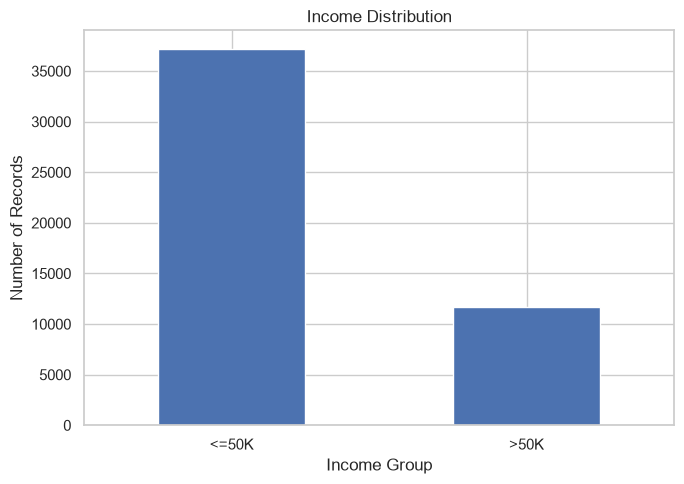

In [211]:
income_counts = df["income"].value_counts()

plt.figure(figsize=(7, 5))

income_counts.plot(kind="bar")

plt.title("Income Distribution")
plt.xlabel("Income Group")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig("C:\\Users\\disha\\OneDrive\\Desktop\\adult_income_eda_report\\reports\\charts\\income_distribution.png")
plt.show()


In [212]:
high_income_rate = df["high_income"].mean() * 100

print(f"Percentage of records with income >50K: {high_income_rate:.2f}%")

Percentage of records with income >50K: 0.00%


In [213]:

Path("../reports/tables").mkdir(parents=True, exist_ok=True)
Path("../reports/charts").mkdir(parents=True, exist_ok=True)

print("Folders created successfully.")

Folders created successfully.


In [214]:
education_summary.to_csv(
    "../reports/tables/education_income_summary.csv",
    index=False
)

print("Education summary table saved successfully.")

Education summary table saved successfully.


In [215]:
# Optional: make charts look cleaner
sns.set_theme(style="whitegrid")

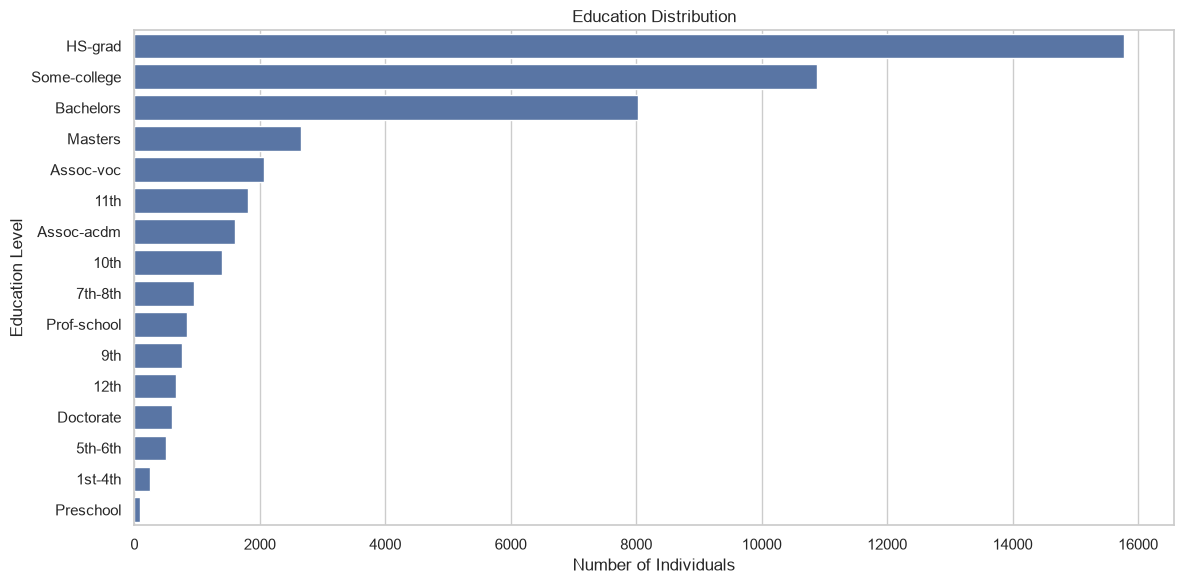

In [216]:
# Education Distribution

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y='education',
    order=df['education'].value_counts().index
)

plt.title('Education Distribution')
plt.xlabel('Number of Individuals')
plt.ylabel('Education Level')
plt.tight_layout()
plt.savefig("C:\\Users\\disha\\OneDrive\\Desktop\\adult_income_eda_report\\reports\\charts\\education_distribution.png")
plt.show()

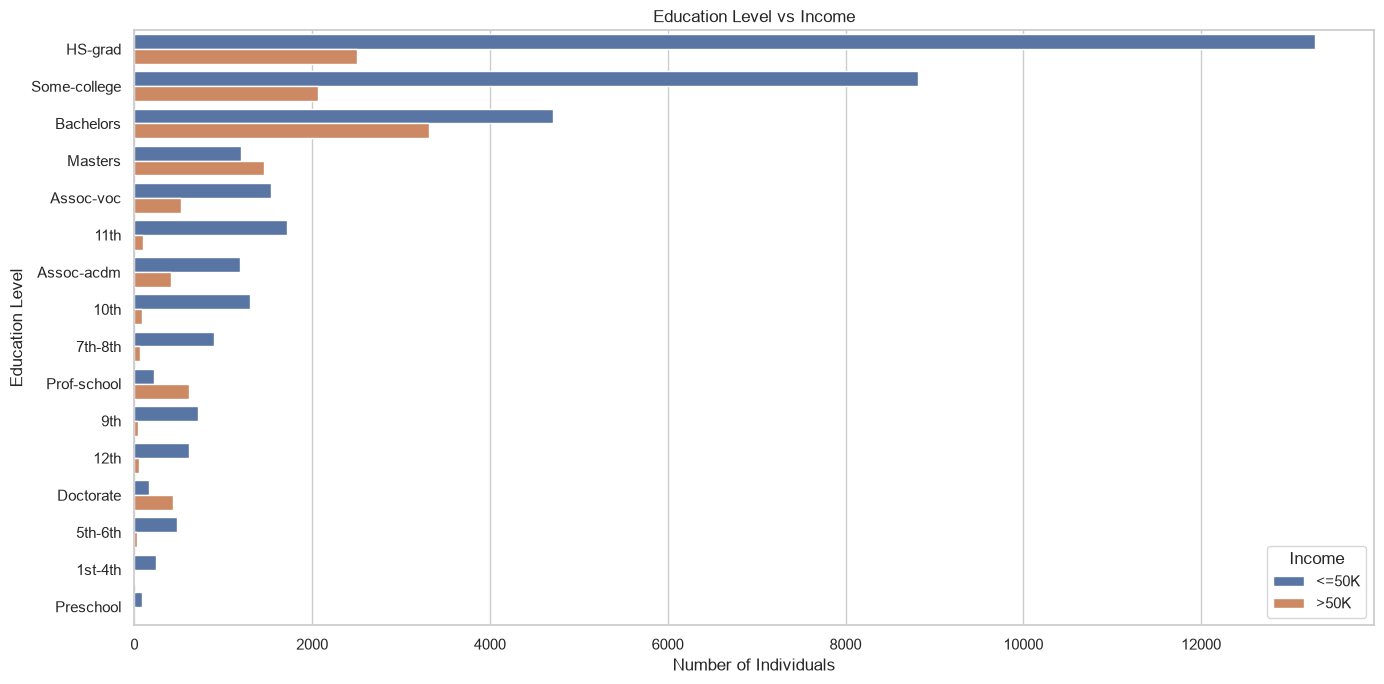

<Figure size 640x480 with 0 Axes>

In [217]:
# Education vs Income

plt.figure(figsize=(14, 7))

sns.countplot(
    data=df,
    y='education',
    hue='income',
    order=df['education'].value_counts().index
)

plt.title('Education Level vs Income')
plt.xlabel('Number of Individuals')
plt.ylabel('Education Level')
plt.legend(title='Income')
plt.tight_layout()
plt.show()
plt.savefig("C:\\Users\\disha\\OneDrive\\Desktop\\adult_income_eda_report\\reports\\charts\\education_vs_income.png")


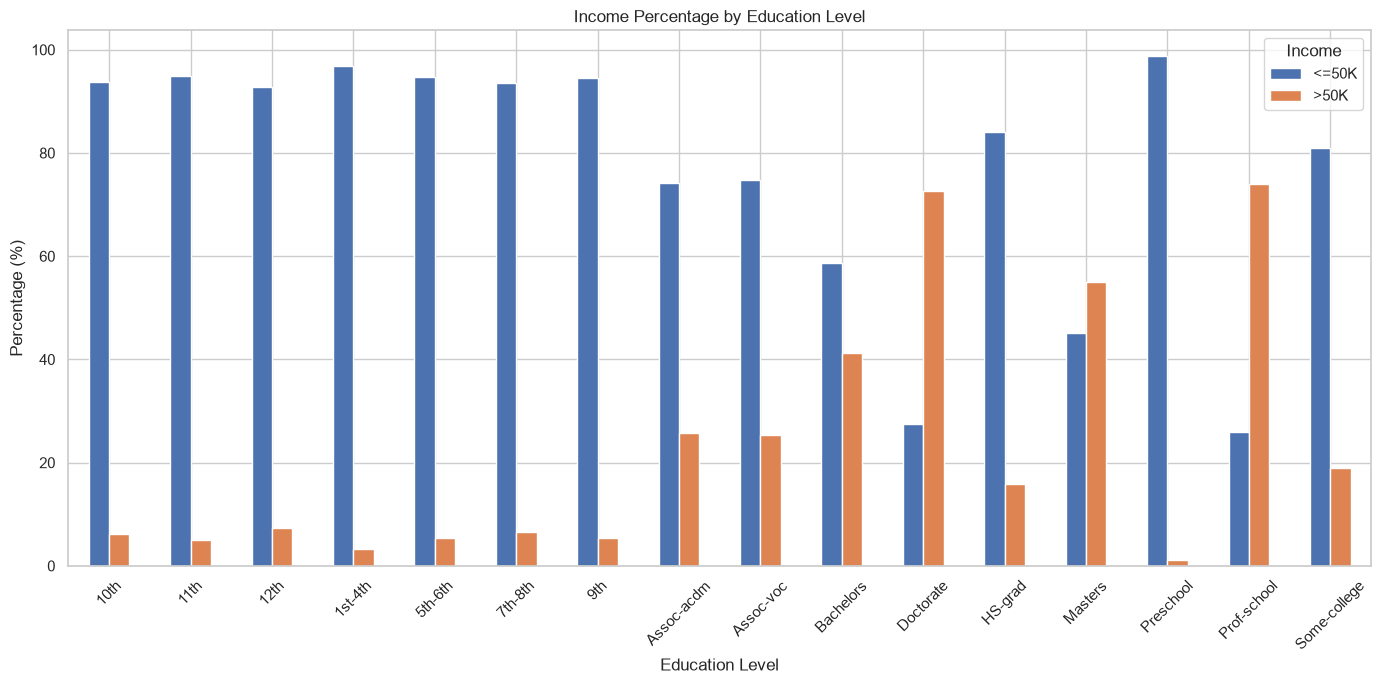

<Figure size 640x480 with 0 Axes>

In [218]:
# with percentage

education_income = pd.crosstab(
    df['education'],
    df['income'],
    normalize='index'
) * 100

education_income.plot(
    kind='bar',
    figsize=(14, 7)
)

plt.title('Income Percentage by Education Level')
plt.xlabel('Education Level')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=45)
plt.legend(title='Income')
plt.tight_layout()
plt.show()
plt.savefig("C:\\Users\\disha\\OneDrive\\Desktop\\adult_income_eda_report\\reports\\charts")

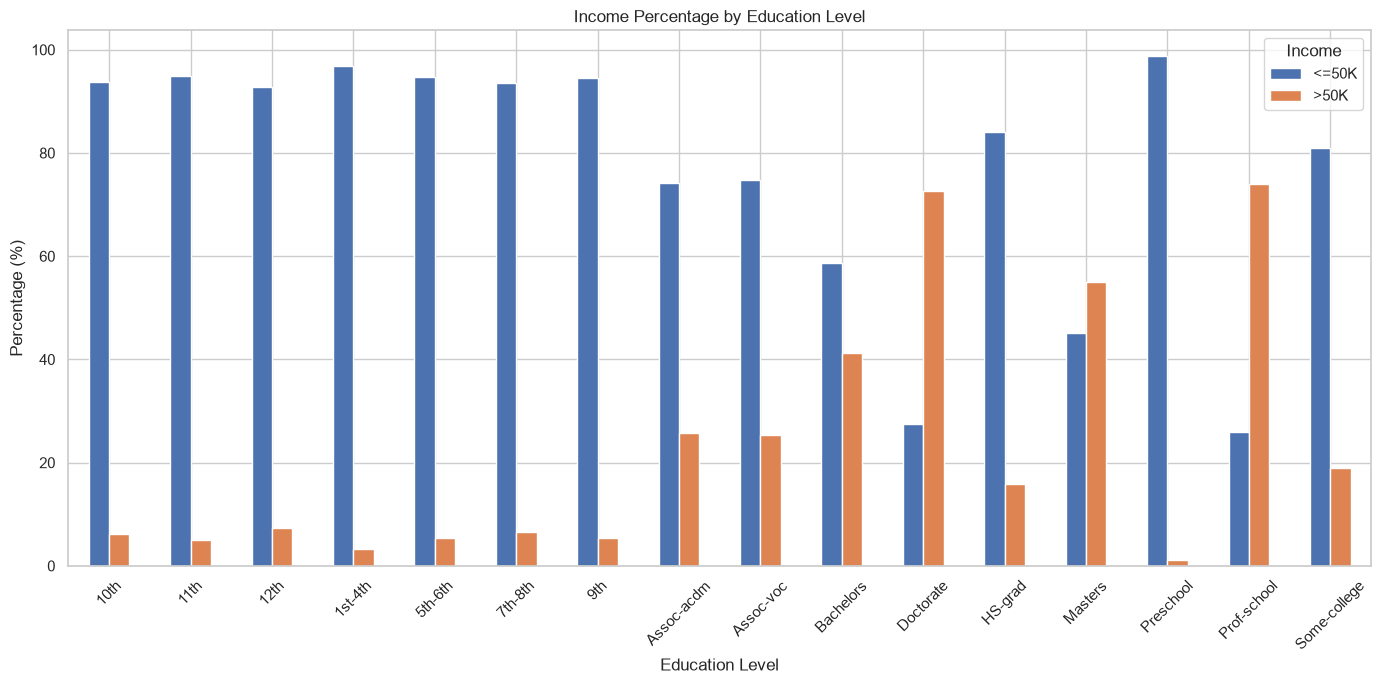

<Figure size 640x480 with 0 Axes>

In [219]:
# Occupation vs Income

education_income = pd.crosstab(
    df['education'],
    df['income'],
    normalize='index'
) * 100

education_income.plot(
    kind='bar',
    figsize=(14, 7)
)

plt.title('Income Percentage by Education Level')
plt.xlabel('Education Level')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=45)
plt.legend(title='Income')
plt.tight_layout()
plt.show()
plt.savefig("C:\\Users\\disha\\OneDrive\\Desktop\\adult_income_eda_report\\reports\\charts")

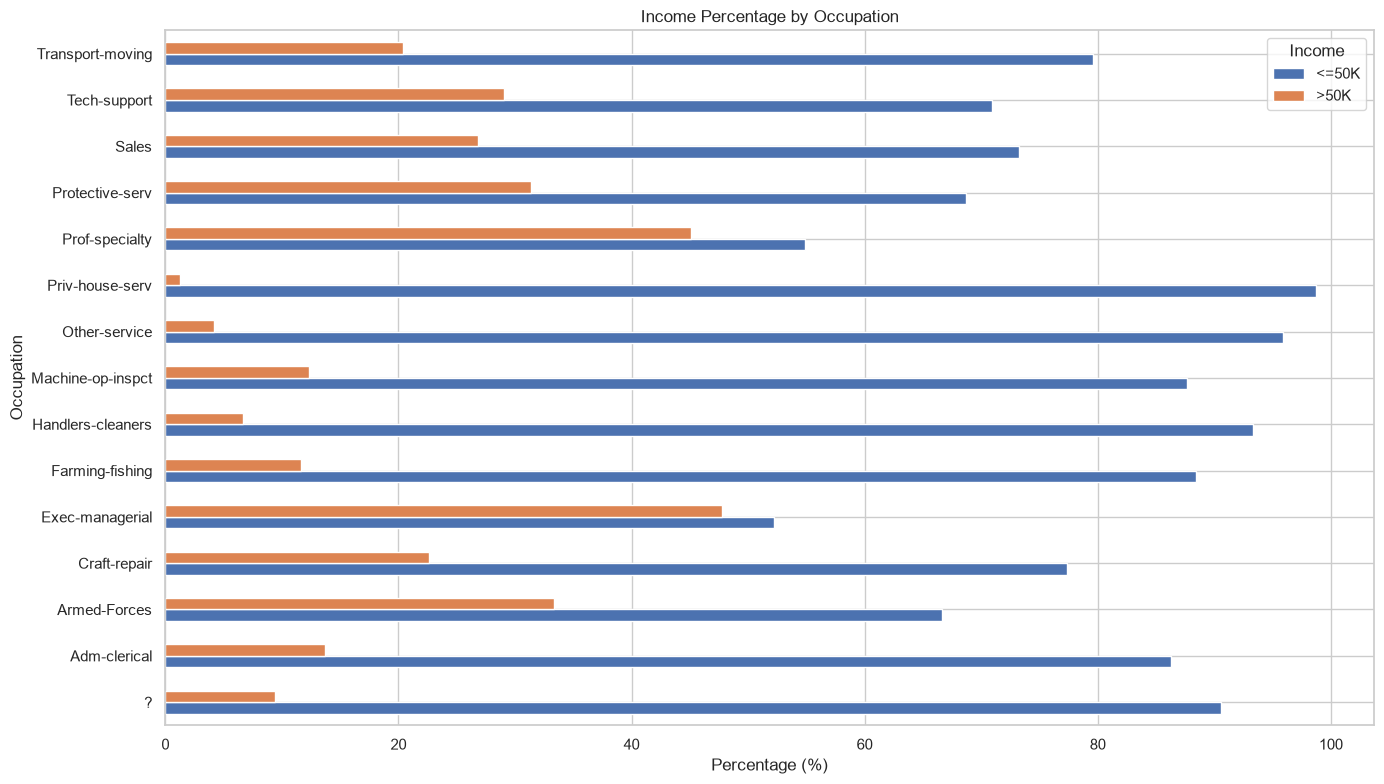

<Figure size 640x480 with 0 Axes>

In [220]:
# with percentage

occupation_income = pd.crosstab(
    df['occupation'],
    df['income'],
    normalize='index'
) * 100

occupation_income.plot(
    kind='barh',
    figsize=(14, 8)
)

plt.title('Income Percentage by Occupation')
plt.xlabel('Percentage (%)')
plt.ylabel('Occupation')
plt.legend(title='Income')
plt.tight_layout()
plt.show()
plt.savefig("C:\\Users\\disha\\OneDrive\\Desktop\\adult_income_eda_report\\reports\\charts\\occupation_vs_income.png")

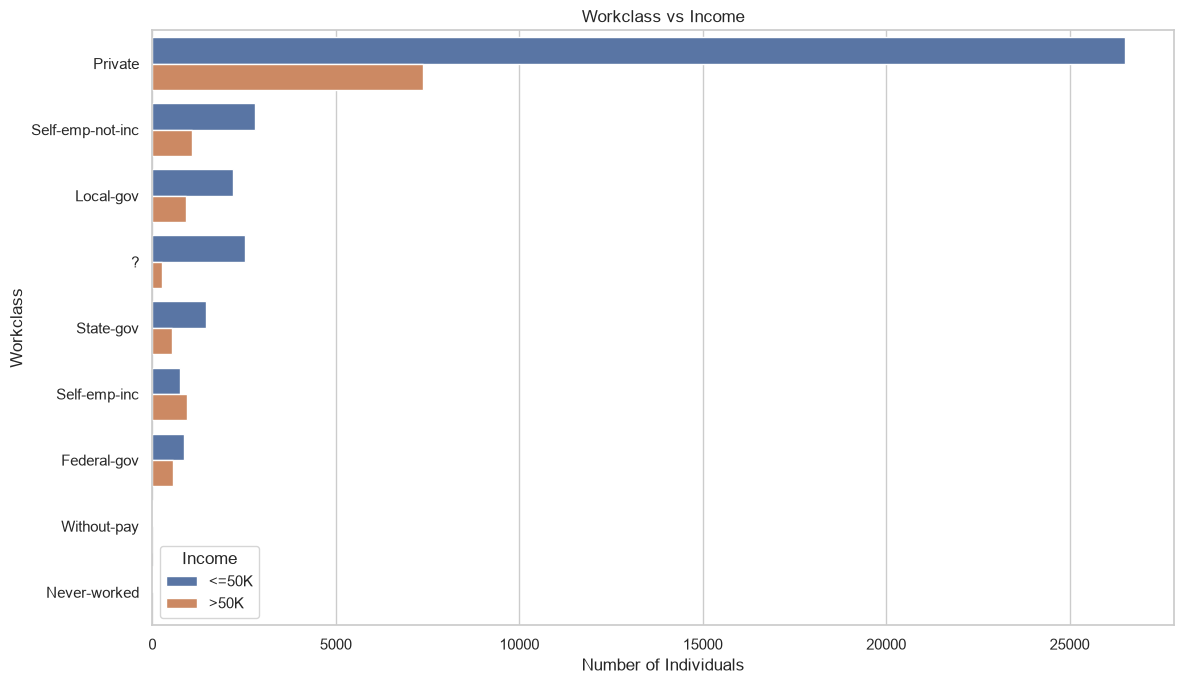

In [221]:
# Workclass vs Income

plt.figure(figsize=(12, 7))

sns.countplot(
    data=df,
    y='workclass',
    hue='income',
    order=df['workclass'].value_counts().index
)

plt.title('Workclass vs Income')
plt.xlabel('Number of Individuals')
plt.ylabel('Workclass')
plt.legend(title='Income')
plt.tight_layout()
plt.savefig("C:\\Users\\disha\\OneDrive\\Desktop\\adult_income_eda_report\\reports\\charts\\workclass_vs_income.png")
plt.show()

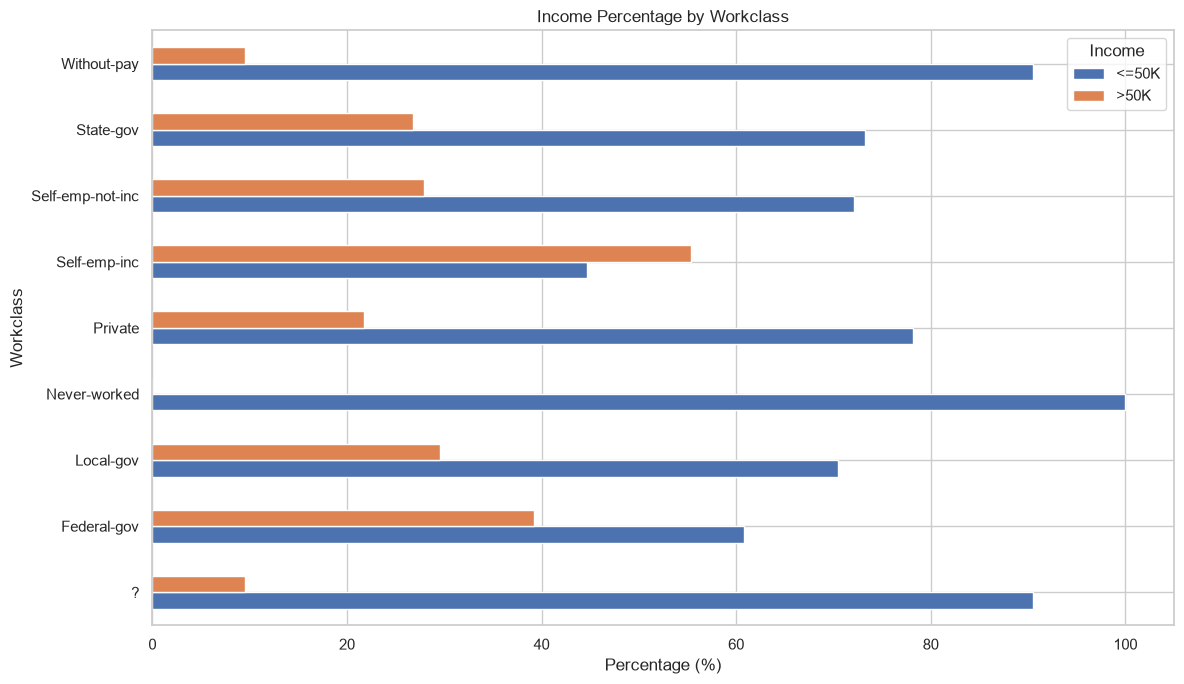

In [222]:
# with percentage

workclass_income = pd.crosstab(
    df['workclass'],
    df['income'],
    normalize='index'
) * 100

workclass_income.plot(
    kind='barh',
    figsize=(12, 7)
)

plt.title('Income Percentage by Workclass')
plt.xlabel('Percentage (%)')
plt.ylabel('Workclass')
plt.legend(title='Income')
plt.tight_layout()
plt.savefig("C:\\Users\\disha\\OneDrive\\Desktop\\adult_income_eda_report\\reports\\charts\\workclass_vs_income_percentage.png")
plt.show()

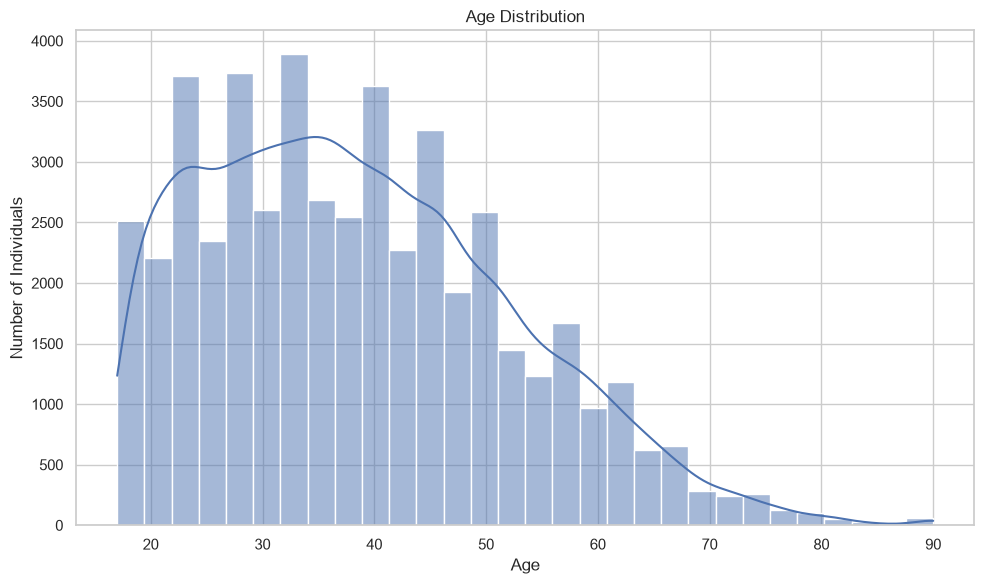

In [223]:
# Age Distribution

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='age',
    bins=30,
    kde=True
)

plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Individuals')
plt.tight_layout()
plt.savefig("C:\\Users\\disha\\OneDrive\\Desktop\\adult_income_eda_report\\reports\\charts\\age_distribution.png")
plt.show()

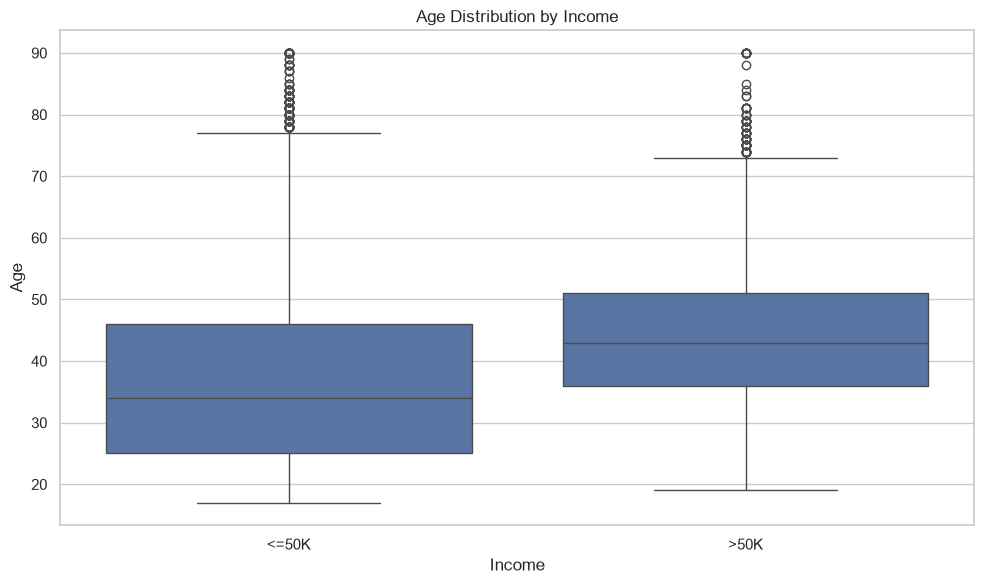

In [224]:
# Age vs Income

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='income',
    y='age'
)

plt.title('Age Distribution by Income')
plt.xlabel('Income')
plt.ylabel('Age')
plt.tight_layout()
plt.savefig("C:\\Users\\disha\\OneDrive\\Desktop\\adult_income_eda_report\\reports\\charts\\age_vs_income.png")
plt.show()

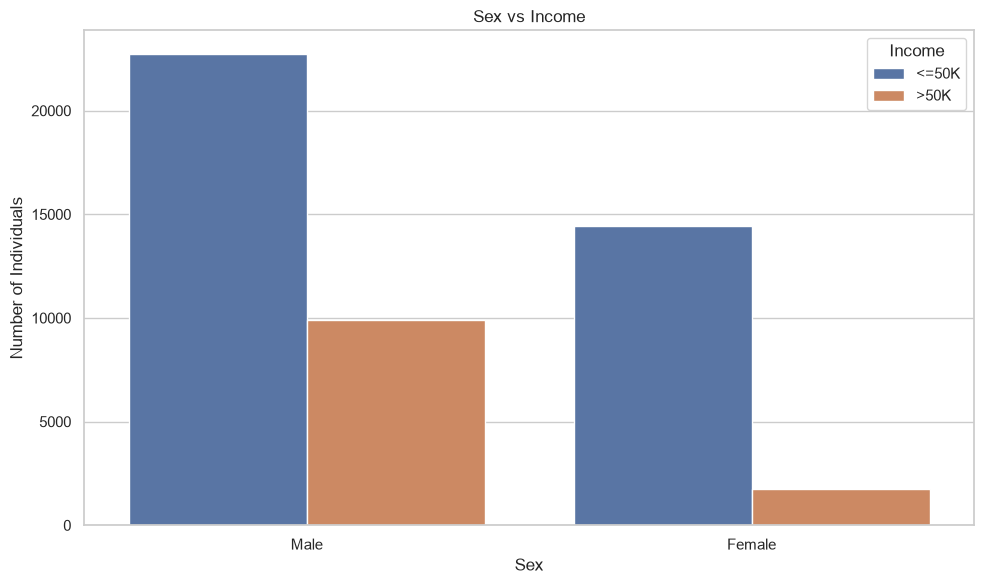

In [225]:
# Sex vs Income

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x='sex',
    hue='income'
)

plt.title('Sex vs Income')
plt.xlabel('Sex')
plt.ylabel('Number of Individuals')
plt.legend(title='Income')
plt.tight_layout()
plt.savefig("C:\\Users\\disha\\OneDrive\\Desktop\\adult_income_eda_report\\reports\\charts\\sex_vs_income.png")
plt.show()

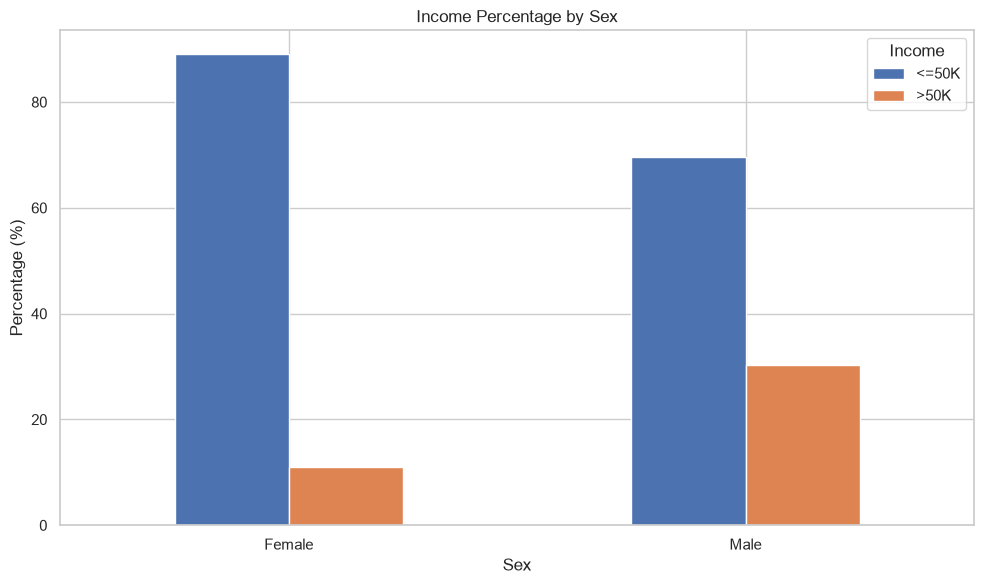

In [226]:
# with percentage

sex_income = pd.crosstab(
    df['sex'],
    df['income'],
    normalize='index'
) * 100

sex_income.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Income Percentage by Sex')
plt.xlabel('Sex')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.legend(title='Income')
plt.tight_layout()
plt.savefig("C:\\Users\\disha\\OneDrive\\Desktop\\adult_income_eda_report\\reports\\charts\\sex_vs_income.png")
plt.show()

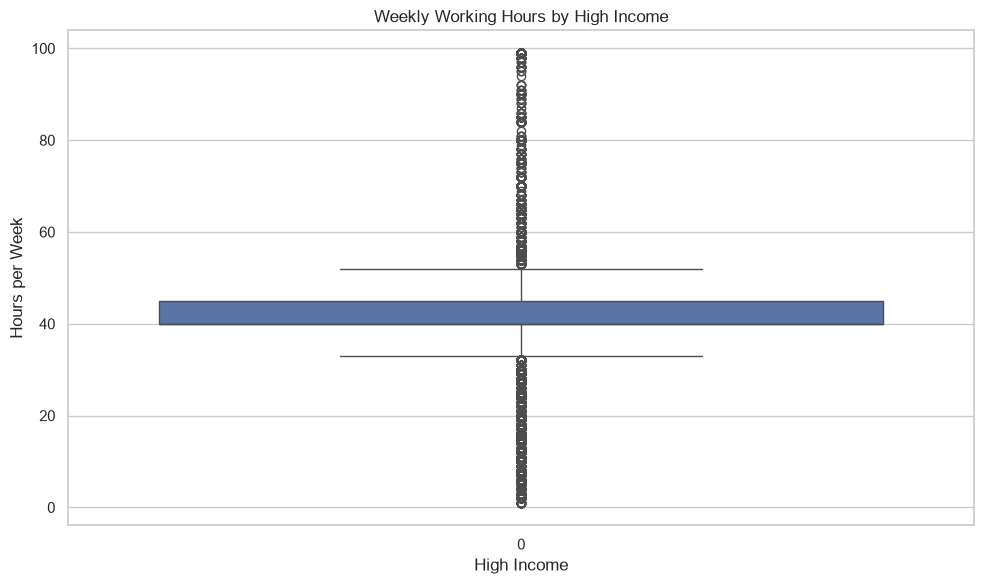

In [227]:
# Hours per Week vs Income

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='high_income',
    y='hours_per_week'
)

plt.title('Weekly Working Hours by High Income')
plt.xlabel('High Income')
plt.ylabel('Hours per Week')

plt.tight_layout()
plt.savefig("C:\\Users\\disha\\OneDrive\\Desktop\\adult_income_eda_report\\reports\\charts\\hours_per_week_vs_income.png")
plt.show()

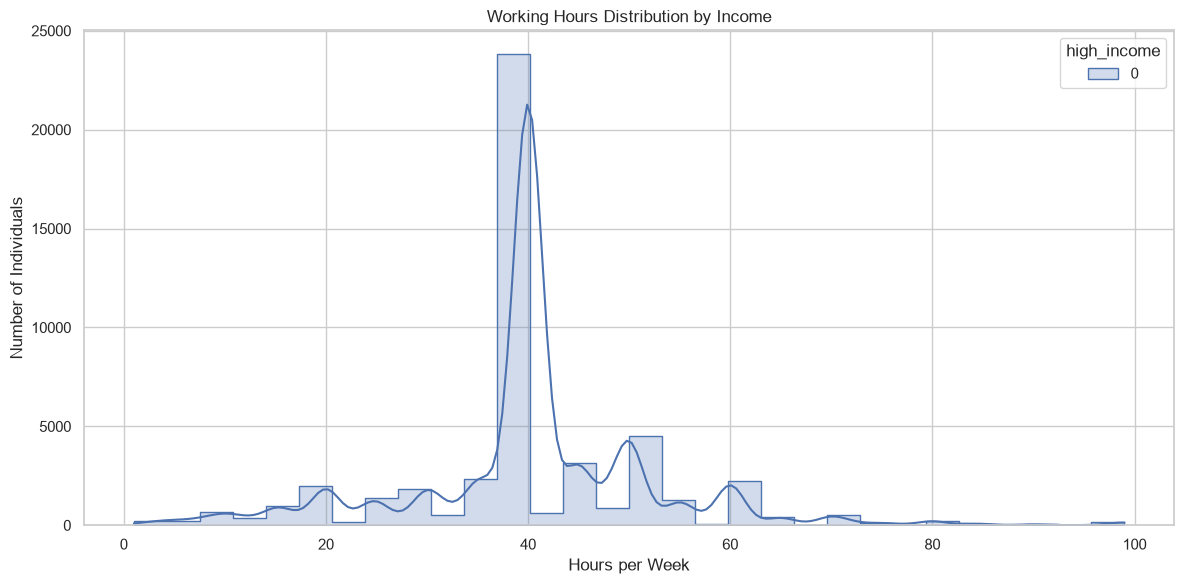

In [228]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x='hours_per_week',
    hue='high_income',
    bins=30,
    kde=True,
    element='step'
)

plt.title('Working Hours Distribution by Income')
plt.xlabel('Hours per Week')
plt.ylabel('Number of Individuals')

plt.tight_layout()
plt.savefig("C:\\Users\\disha\\OneDrive\\Desktop\\adult_income_eda_report\\reports\\charts\\working_hours_distribution_by_income.png")
plt.show()

In [229]:
print(df.columns.tolist())

['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income', 'source_split', 'high_income', 'hours_group', 'net_capital']


In [230]:
numeric_cols = [
    'age',
    'fnlwgt',
    'education_num',
    'capital_gain',
    'capital_loss',
    'hours_per_week',
    'high_income',
    'net_capital'
]

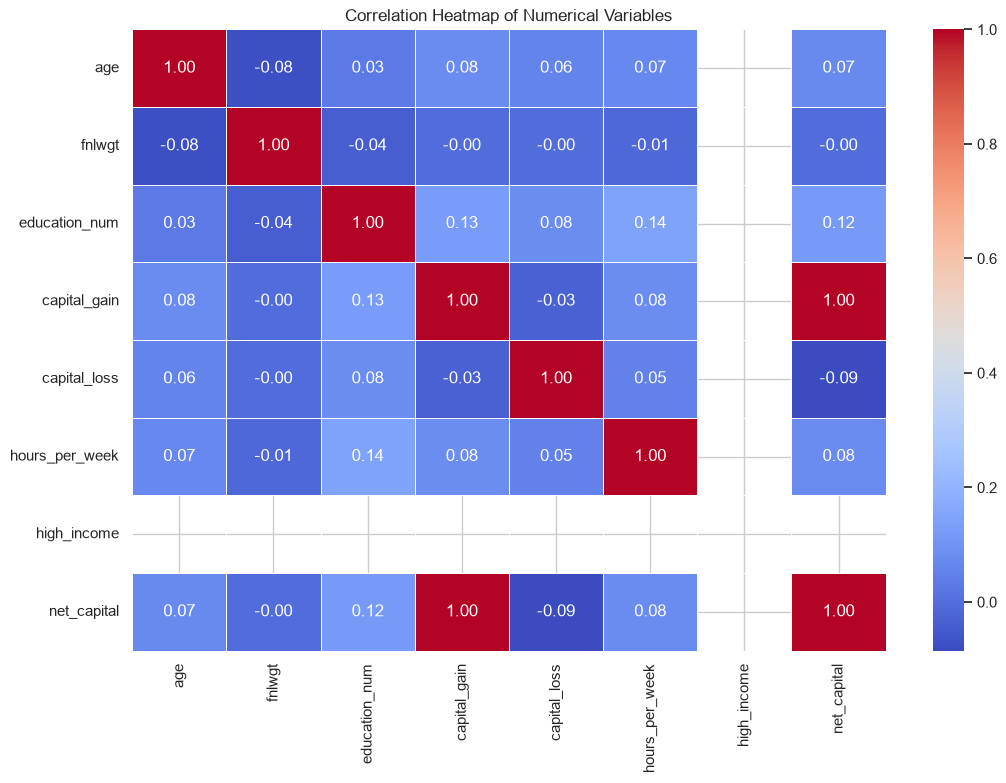

In [231]:
correlation_matrix = df[numeric_cols].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numerical Variables')

plt.tight_layout()
plt.savefig("C:\\Users\\disha\\OneDrive\\Desktop\\adult_income_eda_report\\reports\\charts\\correlation_heatmap.png")
plt.show()

# Numeric Analysis

In [232]:
numeric_cols = [
    'age',
    'fnlwgt',
    'education_num',
    'capital_gain',
    'capital_loss',
    'hours_per_week',
    'net_capital'
]

numeric_summary = df[numeric_cols].describe().T

print(numeric_summary)

                  count           mean            std      min       25%  \
age             48842.0      38.643585      13.710510     17.0      28.0   
fnlwgt          48842.0  189664.134597  105604.025423  12285.0  117550.5   
education_num   48842.0      10.078089       2.570973      1.0       9.0   
capital_gain    48842.0    1079.067626    7452.019058      0.0       0.0   
capital_loss    48842.0      87.502314     403.004552      0.0       0.0   
hours_per_week  48842.0      40.422382      12.391444      1.0      40.0   
net_capital     48842.0     991.565313    7475.549906  -4356.0       0.0   

                     50%       75%        max  
age                 37.0      48.0       90.0  
fnlwgt          178144.5  237642.0  1490400.0  
education_num       10.0      12.0       16.0  
capital_gain         0.0       0.0    99999.0  
capital_loss         0.0       0.0     4356.0  
hours_per_week      40.0      45.0       99.0  
net_capital          0.0       0.0    99999.0  


In [233]:
income_numeric_summary = df.groupby('high_income')[numeric_cols].agg(
    ['mean', 'median']
)

print(income_numeric_summary)

                   age                fnlwgt           education_num         \
                  mean median           mean    median          mean median   
high_income                                                                   
0            38.643585   37.0  189664.134597  178144.5     10.078089   10.0   

            capital_gain        capital_loss        hours_per_week         \
                    mean median         mean median           mean median   
high_income                                                                 
0            1079.067626    0.0    87.502314    0.0      40.422382   40.0   

            net_capital         
                   mean median  
high_income                     
0            991.565313    0.0  


In [234]:
# Correlation Matrix

correlation_matrix = df[numeric_cols].corr()

print(correlation_matrix.round(2))

                 age  fnlwgt  education_num  capital_gain  capital_loss  \
age             1.00   -0.08           0.03          0.08          0.06   
fnlwgt         -0.08    1.00          -0.04         -0.00         -0.00   
education_num   0.03   -0.04           1.00          0.13          0.08   
capital_gain    0.08   -0.00           0.13          1.00         -0.03   
capital_loss    0.06   -0.00           0.08         -0.03          1.00   
hours_per_week  0.07   -0.01           0.14          0.08          0.05   
net_capital     0.07   -0.00           0.12          1.00         -0.09   

                hours_per_week  net_capital  
age                       0.07         0.07  
fnlwgt                   -0.01        -0.00  
education_num             0.14         0.12  
capital_gain              0.08         1.00  
capital_loss              0.05        -0.09  
hours_per_week            1.00         0.08  
net_capital               0.08         1.00  


In [235]:
income_correlation = df[numeric_cols + ['high_income']].corr()['high_income']

print(income_correlation.sort_values(ascending=False))

age              NaN
fnlwgt           NaN
education_num    NaN
capital_gain     NaN
capital_loss     NaN
hours_per_week   NaN
net_capital      NaN
high_income      NaN
Name: high_income, dtype: float64


In [236]:
# Age Statistics by Income

age_summary = df.groupby('high_income')['age'].agg(
    ['count', 'mean', 'median', 'min', 'max', 'std']
)

print(age_summary)

             count       mean  median  min  max       std
high_income                                              
0            48842  38.643585    37.0   17   90  13.71051


In [237]:
# Working Hours Statistics by Income

hours_summary = df.groupby('high_income')['hours_per_week'].agg(
    ['count', 'mean', 'median', 'min', 'max', 'std']
)

print(hours_summary)

             count       mean  median  min  max        std
high_income                                               
0            48842  40.422382    40.0    1   99  12.391444


In [238]:
# Education Number Statistics by Income

education_summary = df.groupby('high_income')['education_num'].agg(
    ['count', 'mean', 'median', 'min', 'max', 'std']
)

print(education_summary)

             count       mean  median  min  max       std
high_income                                              
0            48842  10.078089    10.0    1   16  2.570973


In [239]:
# Capital Gain and Loss by Income
capital_summary = df.groupby('high_income')[
    ['capital_gain', 'capital_loss', 'net_capital']
].agg(
    ['mean', 'median', 'max']
)

print(capital_summary)

            capital_gain               capital_loss              net_capital  \
                    mean median    max         mean median   max        mean   
high_income                                                                    
0            1079.067626    0.0  99999    87.502314    0.0  4356  991.565313   

                           
            median    max  
high_income                
0              0.0  99999  


In [240]:
# Check Outliers

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"{col}: {len(outliers)} potential outliers")

age: 216 potential outliers
fnlwgt: 1453 potential outliers
education_num: 1794 potential outliers
capital_gain: 4035 potential outliers
capital_loss: 2282 potential outliers
hours_per_week: 13496 potential outliers
net_capital: 6317 potential outliers


In [241]:
# Engineered hours_group

print(df['hours_group'].value_counts())

hours_group
40       22803
50+       9681
20-34     5804
41-49     4671
35-39     3292
<20       2591
Name: count, dtype: int64


In [242]:
# Compare with income

hours_income = pd.crosstab(
    df['hours_group'],
    df['high_income'],
    normalize='index'
) * 100

print(hours_income.round(2))

high_income      0
hours_group       
20-34        100.0
35-39        100.0
40           100.0
41-49        100.0
50+          100.0
<20          100.0


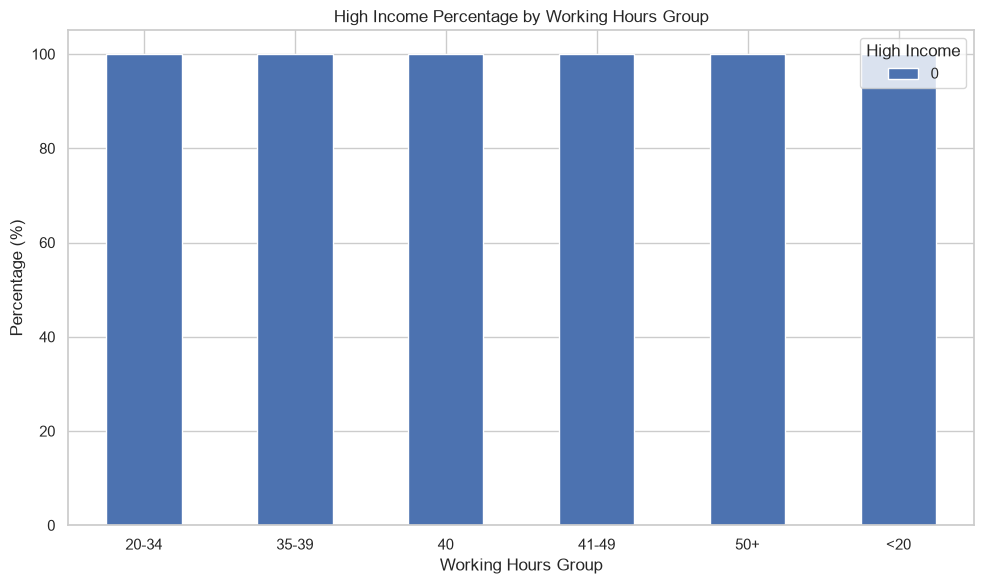

In [243]:
# visualization

hours_income.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('High Income Percentage by Working Hours Group')
plt.xlabel('Working Hours Group')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.legend(title='High Income')

plt.tight_layout()
plt.savefig("C:\\Users\\disha\\OneDrive\\Desktop\\adult_income_eda_report\\reports\\charts\\working_hours_group_vs_income_percentage.png")
plt.show()

In [244]:
# net_capital

print(
    df.groupby('high_income')['net_capital'].agg(
        ['mean', 'median', 'min', 'max']
    )
)

                   mean  median   min    max
high_income                                 
0            991.565313     0.0 -4356  99999


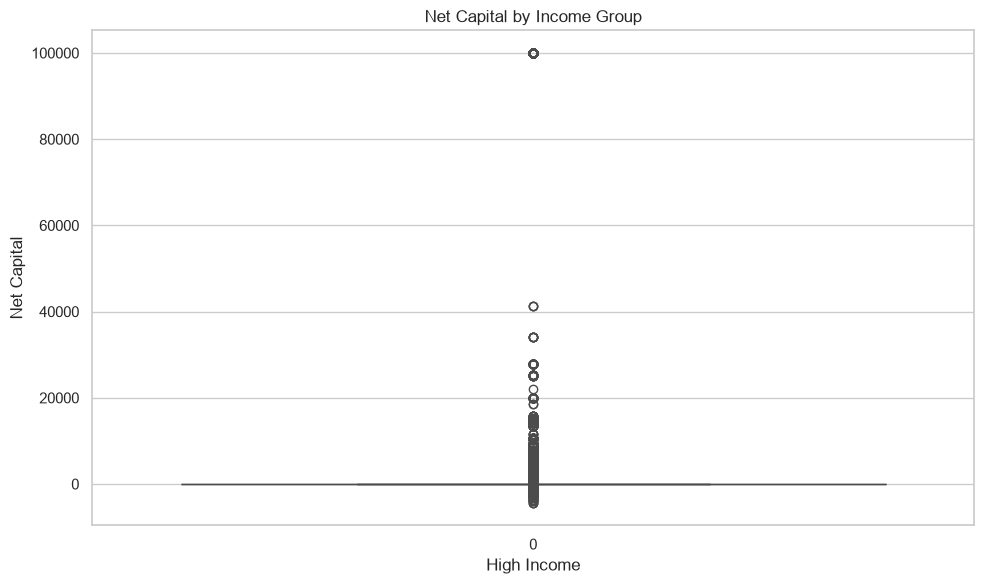

In [245]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='high_income',
    y='net_capital'
)

plt.title('Net Capital by Income Group')
plt.xlabel('High Income')
plt.ylabel('Net Capital')

plt.tight_layout()
plt.savefig("C:\\Users\\disha\\OneDrive\\Desktop\\adult_income_eda_report\\reports\\charts\\net_capital_vs_income.png")
plt.show()

In [246]:
# Create One Final EDA Summary Table

final_numeric_summary = pd.DataFrame({
    'Mean': df[numeric_cols].mean(),
    'Median': df[numeric_cols].median(),
    'Std Dev': df[numeric_cols].std(),
    'Minimum': df[numeric_cols].min(),
    'Maximum': df[numeric_cols].max()
})

print(final_numeric_summary.round(2))

                     Mean    Median    Std Dev  Minimum  Maximum
age                 38.64      37.0      13.71       17       90
fnlwgt          189664.13  178144.5  105604.03    12285  1490400
education_num       10.08      10.0       2.57        1       16
capital_gain      1079.07       0.0    7452.02        0    99999
capital_loss        87.50       0.0     403.00        0     4356
hours_per_week      40.42      40.0      12.39        1       99
net_capital        991.57       0.0    7475.55    -4356    99999


In [247]:
# Select all numeric columns from the dataset
numeric_cols = df.select_dtypes(include=['number']).columns

# Final EDA Summary Table

final_eda_summary = pd.DataFrame({
    'Mean': df[numeric_cols].mean(),
    'Median': df[numeric_cols].median(),
    'Std Dev': df[numeric_cols].std(),
    'Minimum': df[numeric_cols].min(),
    'Maximum': df[numeric_cols].max(),
    'Missing Values': df[numeric_cols].isnull().sum(),
    'Unique Values': df[numeric_cols].nunique()
})

print(final_eda_summary.round(2))

                     Mean    Median    Std Dev  Minimum  Maximum  \
age                 38.64      37.0      13.71       17       90   
fnlwgt          189664.13  178144.5  105604.03    12285  1490400   
education_num       10.08      10.0       2.57        1       16   
capital_gain      1079.07       0.0    7452.02        0    99999   
capital_loss        87.50       0.0     403.00        0     4356   
hours_per_week      40.42      40.0      12.39        1       99   
high_income          0.00       0.0       0.00        0        0   
net_capital        991.57       0.0    7475.55    -4356    99999   

                Missing Values  Unique Values  
age                          0             74  
fnlwgt                       0          28523  
education_num                0             16  
capital_gain                 0            123  
capital_loss                 0             99  
hours_per_week               0             96  
high_income                  0              1  
net

In [248]:
print("Income values:")
print(df['income'].value_counts(dropna=False))

print("\nHigh income values:")
print(df['high_income'].value_counts(dropna=False))

print("\nSample:")
print(df[['income', 'high_income']].head(20))

Income values:
income
<=50K    37155
>50K     11687
Name: count, dtype: int64

High income values:
high_income
0    48842
Name: count, dtype: int64

Sample:
   income  high_income
0   <=50K            0
1   <=50K            0
2   <=50K            0
3   <=50K            0
4   <=50K            0
5   <=50K            0
6   <=50K            0
7    >50K            0
8    >50K            0
9    >50K            0
10   >50K            0
11   >50K            0
12  <=50K            0
13  <=50K            0
14   >50K            0
15  <=50K            0
16  <=50K            0
17  <=50K            0
18  <=50K            0
19   >50K            0


In [249]:
print(df['income'].unique())

<StringArray>
['<=50K', '>50K']
Length: 2, dtype: str


In [250]:
df['income'] = df['income'].str.strip()
df['high_income'] = (df['income'] == '>50K').astype(int)

In [251]:
print(df[['income', 'high_income']].head(20))

   income  high_income
0   <=50K            0
1   <=50K            0
2   <=50K            0
3   <=50K            0
4   <=50K            0
5   <=50K            0
6   <=50K            0
7    >50K            1
8    >50K            1
9    >50K            1
10   >50K            1
11   >50K            1
12  <=50K            0
13  <=50K            0
14   >50K            1
15  <=50K            0
16  <=50K            0
17  <=50K            0
18  <=50K            0
19   >50K            1


In [252]:
print(df['high_income'].value_counts())

high_income
0    37155
1    11687
Name: count, dtype: int64


In [253]:
print(df['high_income'].value_counts(normalize=True) * 100)

high_income
0    76.071823
1    23.928177
Name: proportion, dtype: float64


In [254]:
from pathlib import Path

tables_dir = Path("../reports/tables")
tables_dir.mkdir(parents=True, exist_ok=True)

print(tables_dir.resolve())

C:\Users\disha\OneDrive\Desktop\adult_income_eda_report\reports\tables
